In [1]:
# Assignment 4: Vehicle Price Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-4-Vehicle-Price-Prediction\automobile.csv"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 205
Number of columns: 26

Column Names:
['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num-of-doors       205 non-null    str    
 6   body-style         205 non-null    str    
 7   drive-wheels       205 non-null

In [4]:
df = df.replace("?", np.nan)

numeric_columns = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm",
    "price"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column])

print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values per column:
normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


In [5]:
df = df.dropna(subset=["price"])

for column in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]:
    df[column] = df[column].fillna(df[column].median())

df["num-of-doors"] = df["num-of-doors"].fillna(
    df["num-of-doors"].mode()[0]
)

print("Total missing values remaining:", df.isnull().sum().sum())
print("Shape:", df.shape)

Total missing values remaining: 0
Shape: (201, 26)


In [6]:
word_to_number = {
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "six": 6,
    "eight": 8,
    "twelve": 12
}

df["num-of-doors"] = df["num-of-doors"].map(word_to_number)
df["num-of-cylinders"] = df["num-of-cylinders"].map(word_to_number)

df[["num-of-doors", "num-of-cylinders"]].head()

,num-of-doors,num-of-cylinders
0,2,4
1,2,4
2,2,6
3,4,4
4,4,5


In [7]:
df["price"].describe()

count      201.000000
mean     13207.129353
std       7947.066342
min       5118.000000
25%       7775.000000
50%      10295.000000
75%      16500.000000
max      45400.000000
Name: price, dtype: float64

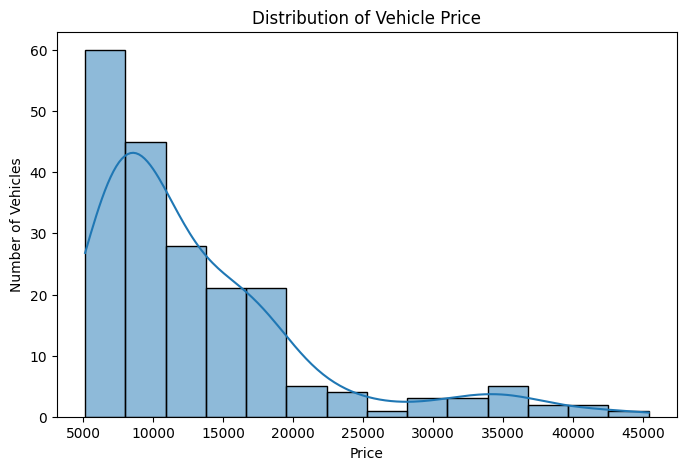

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["price"],
    kde=True
)

plt.title("Distribution of Vehicle Price")
plt.xlabel("Price")
plt.ylabel("Number of Vehicles")
plt.show()

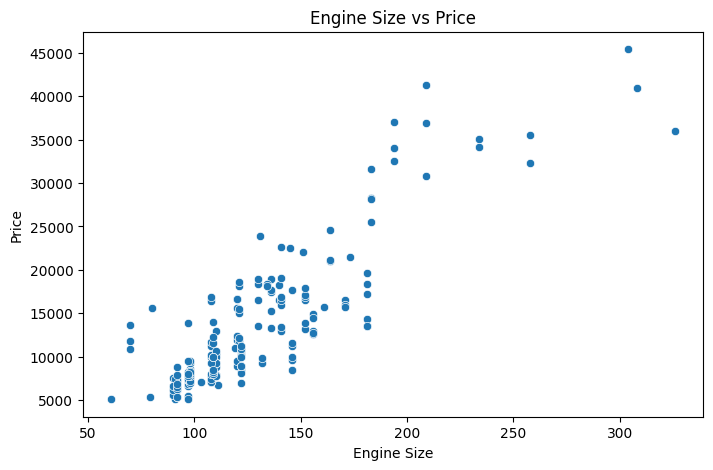

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="engine-size",
    y="price"
)

plt.title("Engine Size vs Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.show()

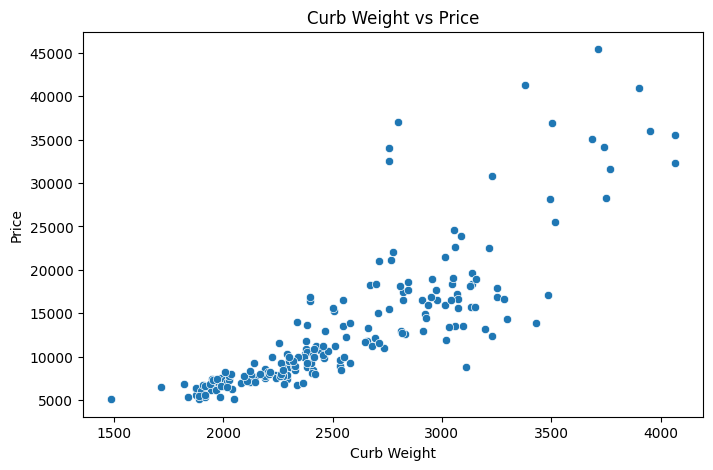

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="curb-weight",
    y="price"
)

plt.title("Curb Weight vs Price")
plt.xlabel("Curb Weight")
plt.ylabel("Price")
plt.show()

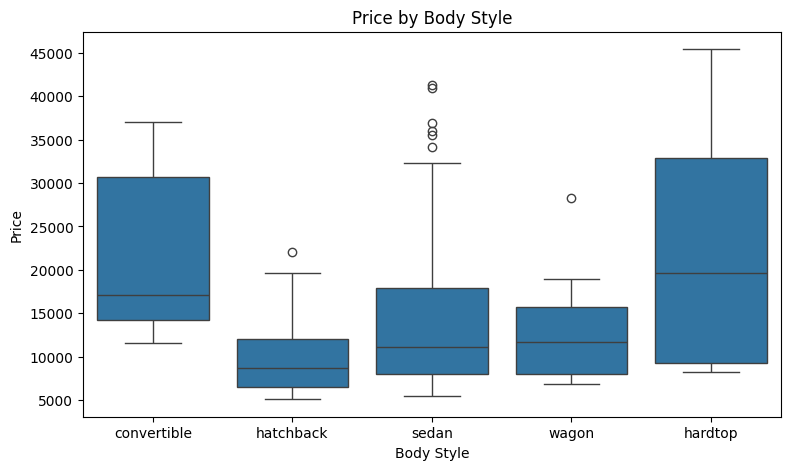

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="body-style",
    y="price"
)

plt.title("Price by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.show()

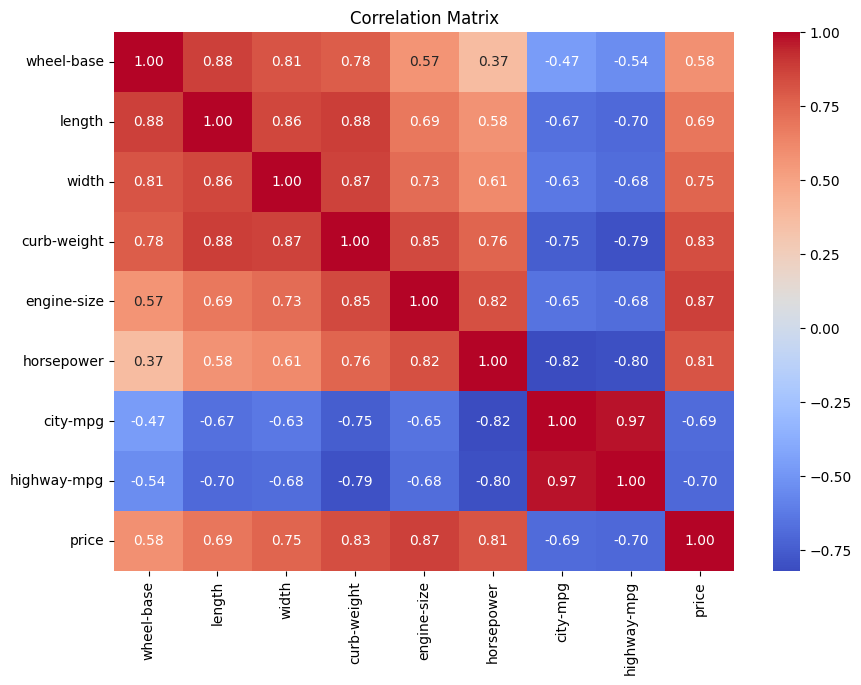

In [12]:
correlation_columns = [
    "wheel-base",
    "length",
    "width",
    "curb-weight",
    "engine-size",
    "horsepower",
    "city-mpg",
    "highway-mpg",
    "price"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [13]:
print("Correlation with price:")
print(
    df[correlation_columns]
    .corr()["price"]
    .sort_values(ascending=False)
)

Correlation with price:
price          1.000000
engine-size    0.872335
curb-weight    0.834415
horsepower     0.810500
width          0.751265
length         0.690628
wheel-base     0.584642
city-mpg      -0.686571
highway-mpg   -0.704692
Name: price, dtype: float64


In [14]:
categorical_columns = [
    "make",
    "fuel-type",
    "aspiration",
    "body-style",
    "drive-wheels",
    "engine-location",
    "engine-type",
    "fuel-system"
]

df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", df.shape)

Shape after encoding: (201, 60)


In [15]:
X = df.drop("price", axis=1)
y = df["price"]

print("Number of features:", X.shape[1])
print("Target column: price")

Number of features: 59
Target column: price


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 160
Testing samples: 41


In [17]:
results = []


def evaluate_model(name, model):
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2": round(r2, 3)
    })

    print(name)
    print("MAE  :", round(mae, 2))
    print("RMSE :", round(rmse, 2))
    print("R2   :", round(r2, 3))

    return predictions

In [18]:
linear_model = LinearRegression()

linear_predictions = evaluate_model(
    "Linear Regression",
    linear_model
)

Linear Regression
MAE  : 1694.45
RMSE : 2755.96
R2   : 0.938


In [19]:
tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_predictions = evaluate_model(
    "Decision Tree",
    tree_model
)

Decision Tree
MAE  : 1811.24
RMSE : 2729.55
R2   : 0.939


In [20]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forest_predictions = evaluate_model(
    "Random Forest",
    forest_model
)

Random Forest
MAE  : 1832.68
RMSE : 2874.55
R2   : 0.932


In [21]:
results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2
0,Linear Regression,1694.45,2755.96,0.938
1,Decision Tree,1811.24,2729.55,0.939
2,Random Forest,1832.68,2874.55,0.932


In [22]:
# A single train test split can favour one model by chance,
# so the models are also compared using 5 fold cross validation
folds = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for name, model in [
    ("Linear Regression", linear_model),
    ("Decision Tree", tree_model),
    ("Random Forest", forest_model)
]:
    scores = cross_val_score(
        model,
        X,
        y,
        cv=folds,
        scoring="r2"
    )

    cv_scores.append(round(scores.mean(), 3))

    print(name, ": average R2 across 5 folds =", round(scores.mean(), 3))

results_df["CV R2"] = cv_scores

results_df.sort_values(
    by="CV R2",
    ascending=False
)

Linear Regression : average R2 across 5 folds = 0.848


Decision Tree : average R2 across 5 folds = 0.856


Random Forest : average R2 across 5 folds = 0.875


,Model,MAE,RMSE,R2,CV R2
2,Random Forest,1832.68,2874.55,0.932,0.875
1,Decision Tree,1811.24,2729.55,0.939,0.856
0,Linear Regression,1694.45,2755.96,0.938,0.848


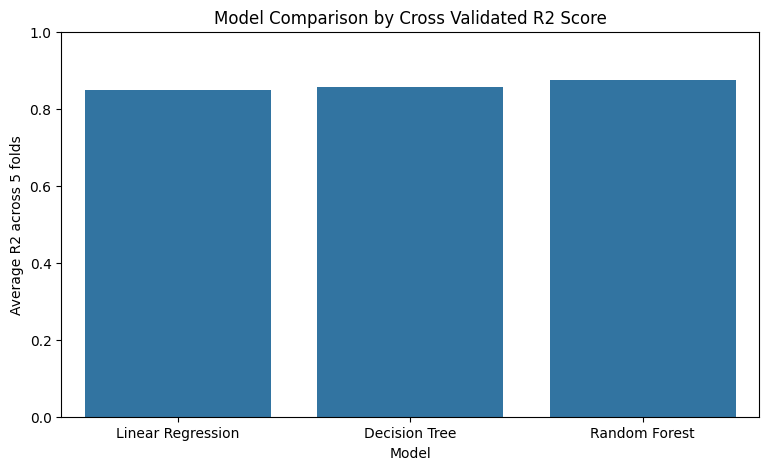

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="CV R2"
)

plt.title("Model Comparison by Cross Validated R2 Score")
plt.xlabel("Model")
plt.ylabel("Average R2 across 5 folds")
plt.ylim(0, 1)
plt.show()

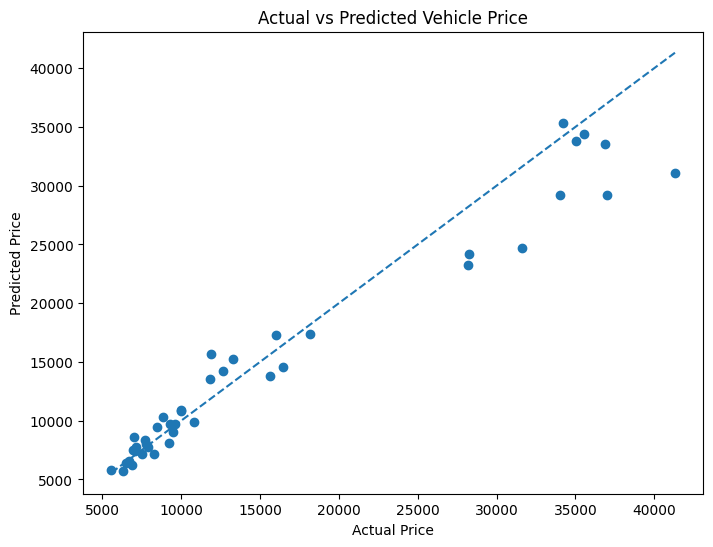

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    forest_predictions
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Vehicle Price")
plt.show()

In [25]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": forest_model.feature_importances_
})

top_features = importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

top_features

,Feature,Importance
7,curb-weight,0.434342
9,engine-size,0.298562
13,horsepower,0.059594
16,highway-mpg,0.058762
15,city-mpg,0.033381
5,width,0.029387
3,wheel-base,0.011659
18,make_bmw,0.009510
8,num-of-cylinders,0.007987
4,length,0.007572


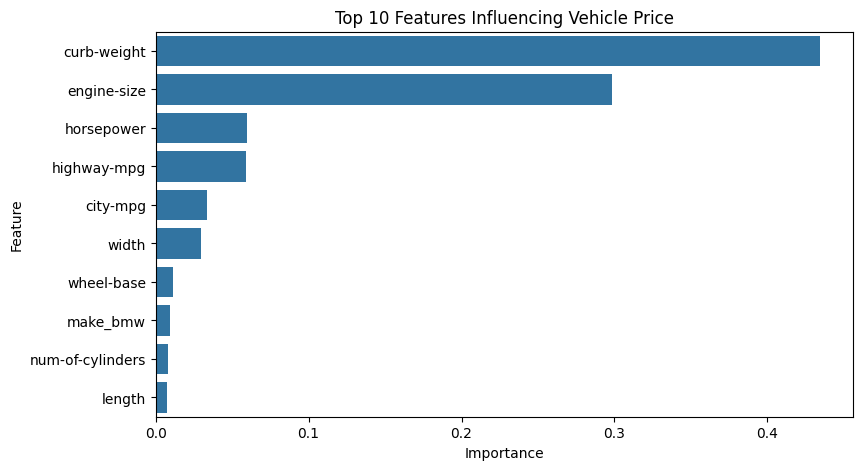

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Vehicle Price")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [27]:
sample_car = X_test.iloc[[0]]

predicted_price = forest_model.predict(sample_car)

print("Actual price    :", round(y_test.iloc[0], 2))
print("Predicted price :", round(predicted_price[0], 2))

Actual price    : 8249.0
Predicted price : 7136.83


In [28]:
best_model = results_df.sort_values(by="CV R2", ascending=False).iloc[0]

print("VEHICLE PRICE PREDICTION - SUMMARY")
print("------------------------------------")
print("Records used   :", df.shape[0])
print("Features used  :", X.shape[1])
print("Best model     :", best_model["Model"])
print("MAE            :", best_model["MAE"])
print("RMSE           :", best_model["RMSE"])
print("Test R2        :", best_model["R2"])
print("CV R2          :", best_model["CV R2"])

VEHICLE PRICE PREDICTION - SUMMARY
------------------------------------
Records used   : 201
Features used  : 59
Best model     : Random Forest
MAE            : 1832.68
RMSE           : 2874.55
Test R2        : 0.932
CV R2          : 0.875
